# 03 – Frozen Encoder
**Coursework Topic 6 – News Topic Classification (AG News)**

Freeze DistilBERT, chỉ train Classification Head.

```
Text → Tokenizer → DistilBERT (FROZEN) → Mean pooling → Head (TRAINED) → 4 lớp
```

In [18]:
import sys
sys.path.append("../src")   # để import models.py khi chạy notebook trong thư mục notebooks/
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import models
from models import LABELS

## 1. Cấu hình
`QUICK_TEST = True` để chạy thử nhanh (Thứ 4). Đổi thành `False` khi chạy chính thức (Thứ 5).

In [19]:
QUICK_TEST = False

if QUICK_TEST:
    cfg = dict(train_size=5000, val_size=1000, test_size=1000)
else:
    cfg = dict(train_size=None, val_size=None, test_size=None)  # toàn bộ AG News

print(cfg)

{'train_size': None, 'val_size': None, 'test_size': None}


## 2. Chạy thí nghiệm
Gồm: load dữ liệu → freeze encoder → trích đặc trưng → train head → đánh giá → lưu metrics, predictions, checkpoint.

In [20]:
out = models.run_experiment(max_len=64, batch_size=64, head_epochs=20, lr=1e-3, seed=42, **cfg)

Device: cpu | backbone: distilbert-base-uncased
train/val/test = 108000/12000/7600
Params: total=66,365,956 trainable=3,076 size=253.2 MB


train feats:   0%|          | 0/1688 [00:00<?, ?it/s]

val feats:   0%|          | 0/188 [00:00<?, ?it/s]

test feats:   0%|          | 0/119 [00:00<?, ?it/s]

Test: acc=0.9034 macroF1=0.9032 | train 3289.5s | infer 182.5s


## 3. Tham số và kích thước mô hình

In [21]:
row = out["row"]
print(f"Total params     : {row['total_params']:,}")
print(f"Trainable params : {row['trainable_params']:,}")
print(f"Model size       : {row['model_size_mb']:.1f} MB (checkpoint head: {row['checkpoint_size_mb']*1024:.1f} KB)")

Total params     : 66,365,956
Trainable params : 3,076
Model size       : 253.2 MB (checkpoint head: 13.8 KB)


## 4. Kết quả trên tập test

In [22]:
metrics = pd.read_csv("../results/metrics/frozen_encoder_metrics.csv")
metrics.T

,0
model,frozen_encoder
backbone,distilbert-base-uncased
accuracy,0.903421
precision_macro,0.903551
recall_macro,0.903421
f1_macro,0.903245
train_time_s,3289.519261
feature_extraction_time_s,3256.526223
head_train_time_s,32.993038
inference_time_s,182.527057


In [23]:
print(classification_report(out["y_true"], out["y_pred"], target_names=LABELS, digits=4))

              precision    recall  f1-score   support

       World     0.9213    0.8937    0.9073      1900
      Sports     0.9581    0.9858    0.9717      1900
    Business     0.8461    0.8768    0.8612      1900
    Sci/Tech     0.8887    0.8574    0.8728      1900

    accuracy                         0.9034      7600
   macro avg     0.9036    0.9034    0.9032      7600
weighted avg     0.9036    0.9034    0.9032      7600



## 5. Learning curve của head

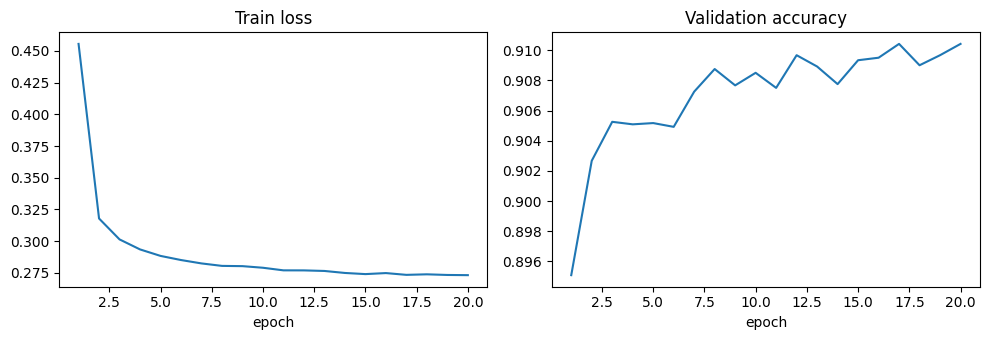

In [24]:
hist = pd.DataFrame(out["history"])
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].plot(hist["epoch"], hist["train_loss"]); ax[0].set_title("Train loss"); ax[0].set_xlabel("epoch")
ax[1].plot(hist["epoch"], hist["val_accuracy"]); ax[1].set_title("Validation accuracy"); ax[1].set_xlabel("epoch")
plt.tight_layout(); plt.show()

## 6. Confusion matrix (xem nhanh)
Bản chính thức để lưu vào `results/figures/` do `src/evaluate.py` (Trúc Chi) tạo.

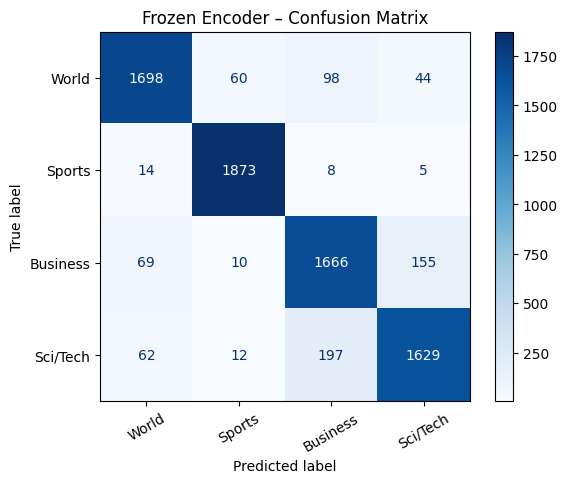

In [25]:
cm = confusion_matrix(out["y_true"], out["y_pred"])
ConfusionMatrixDisplay(cm, display_labels=LABELS).plot(cmap="Blues", xticks_rotation=30)
plt.title("Frozen Encoder – Confusion Matrix"); plt.show()

## 7. Một vài mẫu dự đoán sai

In [26]:
preds = pd.read_csv("../results/metrics/frozen_encoder_predictions.csv")
wrong = preds[~preds["correct"]].sort_values("confidence", ascending=False)
print(f"Sai {len(wrong)}/{len(preds)} mẫu")
wrong[["text", "true_name", "pred_name", "confidence"]].head(10)

Sai 734/7600 mẫu


,text,true_name,pred_name,confidence
6185,Special to ESPN.com It #39;s the age old quest...,Business,Sports,0.998847
7539,Mars water tops science honours The discovery ...,World,Sci/Tech,0.997534
5886,Producer Price Surge Fuels Inflation Fears Pro...,World,Business,0.996899
2613,Embattled Mortgage Giant Agrees to Meet New St...,World,Business,0.996511
5128,Argentina Basketball Coach Magnano Quits Ruben...,World,Sports,0.995958
1494,Telescope snaps distant 'planet' The first dir...,World,Sci/Tech,0.995851
120,Oil prices bubble to record high The price of ...,World,Business,0.995136
5740,Dow Jones Agrees to Buy MarketWatch in \$519 M...,World,Business,0.994303
3563,"Ken Caminiti, 1996 NL MVP, Dies at Age 41 NEW ...",World,Sports,0.993781
3662,"Oil Prices, Earnings Send Stocks Lower NEW YOR...",World,Business,0.993237


## 8. Thử dự đoán một câu

In [27]:
samples = ["Manchester United won the match 3-1.",
           "Apple unveils a new chip for its laptops.",
           "Stocks fell as oil prices surged on Tuesday."]
names, confs = models.predict_texts(out["model"], out["tokenizer"], samples, max_len=64)
for s, n, c in zip(samples, names, confs):
    print(f"{n:9s} ({c:.2f})  {s}")

Sports    (0.95)  Manchester United won the match 3-1.
Sci/Tech  (0.96)  Apple unveils a new chip for its laptops.
Business  (0.99)  Stocks fell as oil prices surged on Tuesday.
